 # Title
 Rainfall Insights Odisha: Hourly Rainfall Pattern Analysis (2022–2025)
# Abstract

This project focuses on the analysis of hourly rainfall telemetry data collected from different stations across Odisha. The dataset is analyzed using Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn. The main objective is to explore rainfall readings, identify monthly and yearly patterns, compare station-wise data, and examine unusual or inconsistent values. Data cleaning and exploratory data analysis are performed before creating visualizations. The findings aim to improve understanding of the available rainfall data and highlight data-quality issues that may require further verification.

# Section 1: Dataset Loading and Initial Exploration

## Import Libraries

The required Python libraries are imported for data loading, analysis, and visualization.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ModuleNotFoundError: No module named 'seaborn'

In [3]:
%pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
import pandas as pd

df = pd.read_csv("rainfall_tel_hr_odisha_od_2021_2025.csv")

print(df.shape)
print(df.columns.tolist())
print(df.head(10).to_string())
print(df.dtypes)

(119311, 20)
['SlNo', 'Station', 'Agency', 'State LGD Code', 'State', 'District LGD Code', 'District', 'Tehsil', 'Block', 'Village', 'River', 'Basin', 'Tributary', 'Subtributary', 'SubSubtributary', 'Local River', 'Latitude', 'Longitude', 'Data Acquisition Time', 'Telemetry Hourly Rainfall (mm)']
   SlNo      Station  Agency  State LGD Code   State  District LGD Code  District Tehsil Block Village River Basin Tributary Subtributary SubSubtributary Local River  Latitude  Longitude Data Acquisition Time  Telemetry Hourly Rainfall (mm)
0     1  Badanalla_1  Odisha              21  Odisha                370  RAYAGADA      -     -       -     -     -         -            -               -           -    19.308     83.887      05-07-2025 11:00                             1.0
1     2  Badanalla_1  Odisha              21  Odisha                370  RAYAGADA      -     -       -     -     -         -            -               -           -    19.308     83.887      05-07-2025 12:00            

### Dataset Information

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119311 entries, 0 to 119310
Data columns (total 20 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   SlNo                            119311 non-null  int64  
 1   Station                         119311 non-null  str    
 2   Agency                          119311 non-null  str    
 3   State LGD Code                  119311 non-null  int64  
 4   State                           119311 non-null  str    
 5   District LGD Code               119311 non-null  int64  
 6   District                        119311 non-null  str    
 7   Tehsil                          119311 non-null  str    
 8   Block                           119311 non-null  str    
 9   Village                         119311 non-null  str    
 10  River                           119311 non-null  str    
 11  Basin                           119311 non-null  str    
 12  Tributary                  

### Statistical Summary

In [8]:
df.describe()

,SlNo,State LGD Code,District LGD Code,Latitude,Longitude,Telemetry Hourly Rainfall (mm)
count,119311.000000,119311.0,119311.000000,119311.000000,119311.000000,119311.000000
mean,59656.000000,21.0,360.888133,20.748225,84.741087,97.208751
std,34442.263321,0.0,8.839840,1.143074,1.436342,147.524625
min,1.000000,21.0,344.000000,18.072833,81.554130,-501.000000
25%,29828.500000,21.0,354.000000,19.798065,83.569500,0.500000
50%,59656.000000,21.0,362.000000,20.909798,84.784030,2.500000
75%,89483.500000,21.0,370.000000,21.738700,85.992778,283.000000
max,119311.000000,21.0,373.000000,22.519791,87.280514,511.500000


## Rainfall Data Quality Analysis

This section examines missing rainfall values, negative readings, zero readings, and unusually high recorded values to understand the quality of the dataset.

# Section 2: Data Cleaning and Preprocessing

This section focuses on checking missing values, identifying duplicate records, converting data types, and examining unusual rainfall readings.

In [16]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"
time_col = "Data Acquisition Time"

print("Rainfall quality summary")

print("Total records:", len(df))
print("Missing rainfall:", df[rainfall_col].isna().sum())
print("Negative readings:", (df[rainfall_col] < 0).sum())
print("511.5 readings:", (df[rainfall_col] == 511.5).sum())
print("Zero readings:", (df[rainfall_col] == 0).sum())

print("\nOther rainfall values above 100 mm:")
print(
    df.loc[df[rainfall_col] > 100, rainfall_col]
    .describe()
)

Rainfall quality summary
Total records: 119311
Missing rainfall: 0
Negative readings: 134
511.5 readings: 789
Zero readings: 0

Other rainfall values above 100 mm:
count    35583.000000
mean       319.356996
std         47.368848
min        101.000000
25%        294.500000
50%        320.000000
75%        340.000000
max        511.500000
Name: Telemetry Hourly Rainfall (mm), dtype: float64


### Date-Time Conversion and Year-wise Record Analysis

The date-time column is converted into datetime format to support time-based analysis. The available years, date range, and yearly record counts are then examined.

In [ ]:
# Convert the date/time column into datetime format
df["Data Acquisition Time"] = pd.to_datetime(
    df["Data Acquisition Time"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

# Check available years
print("Available years:")
print(sorted(df["Data Acquisition Time"].dt.year.dropna().unique()))

# Check earliest and latest dates
print("Start date:", df["Data Acquisition Time"].min())
print("End date:", df["Data Acquisition Time"].max())

# Records available in each year
print("\nRecords per year:")
print(df["Data Acquisition Time"].dt.year.value_counts().sort_index())

Available years:
[np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]
Start date: 2022-01-08 15:00:00
End date: 2025-12-30 02:00:00

Records per year:
Data Acquisition Time
2022     2445
2023    14960
2024    52624
2025    49282
Name: count, dtype: int64


### Dataset Structure and Data Quality Checks

The dataset is examined to identify its dimensions, number of unique stations and districts, missing values, duplicate rows, and statistical summary of rainfall readings.

In [3]:
# Check dataset size
print("Dataset shape:", df.shape)

# Check unique stations and districts
print("Total stations:", df["Station"].nunique())
print("Total districts:", df["District"].nunique())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check rainfall statistics
print("\nRainfall summary:")
print(df["Telemetry Hourly Rainfall (mm)"].describe())

Dataset shape: (119311, 20)
Total stations: 124
Total districts: 28

Missing values:
SlNo                              0
Station                           0
Agency                            0
State LGD Code                    0
State                             0
District LGD Code                 0
District                          0
Tehsil                            0
Block                             0
Village                           0
River                             0
Basin                             0
Tributary                         0
Subtributary                      0
SubSubtributary                   0
Local River                       0
Latitude                          0
Longitude                         0
Data Acquisition Time             0
Telemetry Hourly Rainfall (mm)    0
dtype: int64

Duplicate rows: 0

Rainfall summary:
count    119311.000000
mean         97.208751
std         147.524625
min        -501.000000
25%           0.500000
50%           2.500000
75%   

### Duplicate Records and Rainfall Value Checks

This step checks for duplicate rows, repeated station-time records, negative rainfall readings, zero readings, and the statistical distribution of rainfall values.

In [4]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check duplicate station-time records
print(
    "Duplicate station-time records:",
    df.duplicated(
        subset=["Station", "Data Acquisition Time"]
    ).sum()
)

# Check rainfall values
rainfall_col = "Telemetry Hourly Rainfall (mm)"

print("\nNegative rainfall readings:",
      (df[rainfall_col] < 0).sum())

print("\nZero rainfall readings:",
      (df[rainfall_col] == 0).sum())

print("\nRainfall summary:")
print(df[rainfall_col].describe().to_string())

Duplicate rows: 0
Duplicate station-time records: 17569

Negative rainfall readings: 134

Zero rainfall readings: 0

Rainfall summary:
count    119311.000000
mean         97.208751
std         147.524625
min        -501.000000
25%           0.500000
50%           2.500000
75%         283.000000
max         511.500000


### Inspection of Unusual and Duplicate Records

This step examines negative rainfall readings, repeated station-time records, and the highest recorded rainfall values to identify observations that may require further verification.

In [5]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"
time_col = "Data Acquisition Time"

# 1. Show negative rainfall records
negative_df = df[df[rainfall_col] < 0]

print("Negative records:")
print(
    negative_df[
        ["Station", "District", time_col, rainfall_col]
    ].head(15).to_string(index=False)
)

# 2. Show duplicate station-time records
duplicate_df = df[
    df.duplicated(
        subset=["Station", time_col],
        keep=False
    )
]

print("\nDuplicate station-time examples:")
print(
    duplicate_df[
        ["Station", "District", time_col, rainfall_col]
    ].sort_values(["Station", time_col]).head(20).to_string(index=False)
)

# 3. Inspect highest rainfall readings
print("\nHighest rainfall readings:")
print(
    df.nlargest(10, rainfall_col)[
        ["Station", "District", time_col, rainfall_col]
    ].to_string(index=False)
)

Negative records:
           Station  District Data Acquisition Time  Telemetry Hourly Rainfall (mm)
        Bahanaga_1 Baleshwar   2023-09-15 05:00:00                          -342.0
        Bahanaga_1 Baleshwar   2024-03-11 02:00:00                          -194.0
        Bahanaga_1 Baleshwar   2024-05-26 19:00:00                           -34.5
        Bahanaga_1 Baleshwar   2024-06-08 22:30:00                          -225.0
        Bahanaga_1 Baleshwar   2024-08-25 21:00:00                           -69.5
        Bahanaga_1 Baleshwar   2024-10-27 21:00:00                          -322.0
        Bahanaga_1 Baleshwar   2024-10-31 19:30:00                          -225.0
        Bahanaga_1 Baleshwar   2024-12-22 03:00:00                          -363.0
        Bahanaga_1 Baleshwar   2024-12-23 05:00:00                           -17.0
        Bahanaga_1 Baleshwar   2025-01-02 11:00:00                           -25.5
        Bahanaga_1 Baleshwar   2025-01-19 19:00:00                   

In [6]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"
time_col = "Data Acquisition Time"

duplicate_df = df[
    df.duplicated(
        subset=["Station", time_col],
        keep=False
    )
]

# How many duplicate groups have different rainfall values?
value_counts = (
    duplicate_df.groupby(["Station", time_col])[rainfall_col]
    .nunique()
)

print("Duplicate groups:", len(value_counts))
print("Groups with different readings:", (value_counts > 1).sum())
print("Groups with same readings:", (value_counts == 1).sum())

# Check how often negative values occur
print("\nNegative values frequency:")
print(df.loc[df[rainfall_col] < 0, rainfall_col].value_counts().head(10))

Duplicate groups: 17569
Groups with different readings: 750
Groups with same readings: 16819

Negative values frequency:
Telemetry Hourly Rainfall (mm)
-36.0     8
-225.0    3
-320.5    2
-353.0    2
-476.0    2
-367.0    2
-189.5    2
-452.0    2
-280.0    2
-460.5    2
Name: count, dtype: int64


In [7]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"
time_col = "Data Acquisition Time"

# Select groups with different readings at the same station-time
different_readings = (
    df.groupby(["Station", time_col])[rainfall_col]
    .transform("nunique") > 1
)

print("Examples with different readings:")
print(
    df.loc[
        different_readings,
        ["Station", "District", time_col, rainfall_col]
    ]
    .sort_values(["Station", time_col])
    .head(30)
    .to_string(index=False)
)

Examples with different readings:
              Station   District Data Acquisition Time  Telemetry Hourly Rainfall (mm)
           Bahanaga_1  Baleshwar   2022-10-18 16:00:00                            43.8
           Bahanaga_1  Baleshwar   2022-10-18 16:00:00                            43.5
           Bahanaga_1  Baleshwar   2022-10-18 17:00:00                            43.8
           Bahanaga_1  Baleshwar   2022-10-18 17:00:00                           279.0
           Bahanaga_1  Baleshwar   2023-10-06 12:00:00                           254.0
           Bahanaga_1  Baleshwar   2023-10-06 12:00:00                             0.5
           Bahanaga_1  Baleshwar   2024-03-09 17:00:00                           161.5
           Bahanaga_1  Baleshwar   2024-03-09 17:00:00                             1.0
           Bahanaga_1  Baleshwar   2024-05-26 19:00:00                             6.5
           Bahanaga_1  Baleshwar   2024-05-26 19:00:00                           -34.5
         

In [8]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"
time_col = "Data Acquisition Time"

# Show all readings for one conflicting station and time
sample = df[
    (df["Station"] == "Bahanaga_1") &
    (df[time_col] == pd.Timestamp("2022-10-18 17:00:00"))
]

print(sample.to_string(index=False))

 SlNo    Station Agency  State LGD Code  State  District LGD Code  District Tehsil Block Village River Basin Tributary Subtributary SubSubtributary Local River  Latitude  Longitude Data Acquisition Time  Telemetry Hourly Rainfall (mm)
  228 Bahanaga_1 Odisha              21 Odisha                346 Baleshwar      -     -       -     -     -         -            -               -           - 21.338869   86.75804   2022-10-18 17:00:00                            43.8
  229 Bahanaga_1 Odisha              21 Odisha                346 Baleshwar      -     -       -     -     -         -            -               -           - 21.338869   86.75804   2022-10-18 17:00:00                           279.0


In [9]:
# Count records with conflicting rainfall values
rainfall_col = "Telemetry Hourly Rainfall (mm)"
time_col = "Data Acquisition Time"

conflicts = (
    df.groupby(["Station", time_col])[rainfall_col]
    .nunique()
)

conflicts = conflicts[conflicts > 1]

print("Conflicting station-time groups:", len(conflicts))
print("Records in conflicting groups:",
      df.set_index(["Station", time_col])
        .loc[conflicts.index]
        .shape[0])

Conflicting station-time groups: 750
Records in conflicting groups: 1500


In [10]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"
time_col = "Data Acquisition Time"

conflict_data = (
    df.groupby(["Station", time_col])[rainfall_col]
    .nunique()
    .reset_index(name="different_readings")
)

conflict_data = conflict_data[
    conflict_data["different_readings"] > 1
].copy()

conflict_data["Year"] = conflict_data[time_col].dt.year

print("Year-wise conflicting groups:")
print(conflict_data.groupby("Year").size())

print("\nTop 10 stations with conflicts:")
print(
    conflict_data["Station"]
    .value_counts()
    .head(10)
)

Year-wise conflicting groups:
Year
2022      2
2023    114
2024    587
2025     47
dtype: int64

Top 10 stations with conflicts:
Station
Sagjuri / Hariharjore dam site    100
Tangi_1                            94
Basta_2                            68
Hatibari_1                         45
Morada_1                           45
Barunadihi/Dharuadihi              40
Dasarathpur_1                      38
Kaniha_1                           33
Belbahali_1                        30
Kasipur_1                          29
Name: count, dtype: int64


In [11]:
station_name = "Sagjuri / Hariharjore dam site"

station_conflicts = conflict_data[
    conflict_data["Station"] == station_name
]

sample_times = station_conflicts[time_col].head(5)

sample_records = df[
    (df["Station"] == station_name) &
    (df[time_col].isin(sample_times))
].sort_values(time_col)

sample_records[
    ["Station", time_col, rainfall_col, "District", "Block"]
]

,Station,Data Acquisition Time,Telemetry Hourly Rainfall (mm),District,Block
102060,Sagjuri / Hariharjore dam site,2023-09-12 23:00:00,511.5,SONAPUR,-
102061,Sagjuri / Hariharjore dam site,2023-09-12 23:00:00,0.5,SONAPUR,-
102074,Sagjuri / Hariharjore dam site,2023-09-14 07:00:00,0.5,SONAPUR,-
102075,Sagjuri / Hariharjore dam site,2023-09-14 07:00:00,511.5,SONAPUR,-
102076,Sagjuri / Hariharjore dam site,2023-09-14 08:00:00,1.0,SONAPUR,-
102077,Sagjuri / Hariharjore dam site,2023-09-14 08:00:00,511.5,SONAPUR,-
102087,Sagjuri / Hariharjore dam site,2023-09-14 20:00:00,10.0,SONAPUR,-
102088,Sagjuri / Hariharjore dam site,2023-09-14 20:00:00,511.5,SONAPUR,-
102123,Sagjuri / Hariharjore dam site,2023-09-20 13:00:00,1.0,SONAPUR,-
102124,Sagjuri / Hariharjore dam site,2023-09-20 13:00:00,511.5,SONAPUR,-


In [12]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"

print("Frequency of rainfall values:")
print(df[rainfall_col].value_counts().head(15))

print("\nRecords with rainfall = 511.5:")
print((df[rainfall_col] == 511.5).sum())

print("\nNegative rainfall records:")
print((df[rainfall_col] < 0).sum())

Frequency of rainfall values:
Telemetry Hourly Rainfall (mm)
0.5      35430
1.0      10928
1.5       6998
2.0       4436
2.5       3271
3.0       2594
3.5       2134
4.0       1726
4.5       1327
5.0       1263
5.5       1067
6.0        916
511.5      789
0.1        762
6.5        750
Name: count, dtype: int64

Records with rainfall = 511.5:
789

Negative rainfall records:
134


In [13]:
df[df[rainfall_col] == 511.5][
    ["Station", "District", "Data Acquisition Time", rainfall_col]
].head(15)

,Station,District,Data Acquisition Time,Telemetry Hourly Rainfall (mm)
8064,Barunadihi/Dharuadihi,SUNDARGARH,2023-12-31 15:00:00,511.5
9970,Barunadihi/Dharuadihi,SUNDARGARH,2024-12-19 10:00:00,511.5
10060,Barunadihi/Dharuadihi,SUNDARGARH,2024-12-23 10:00:00,511.5
10087,Barunadihi/Dharuadihi,SUNDARGARH,2024-12-24 13:00:00,511.5
10148,Barunadihi/Dharuadihi,SUNDARGARH,2024-12-31 20:00:00,511.5
10227,Barunadihi/Dharuadihi,SUNDARGARH,2025-01-06 10:00:00,511.5
21301,Chandrapur_2,RAYAGADA,2024-12-09 07:00:00,511.5
21302,Chandrapur_2,RAYAGADA,2024-12-09 08:00:00,511.5
24013,Dasarathpur_1,JAJAPUR,2023-09-12 17:00:00,511.5
24071,Dasarathpur_1,JAJAPUR,2023-10-05 16:00:00,511.5


In [14]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"
time_col = "Data Acquisition Time"

# Check 511.5 readings by year
special_value = df[df[rainfall_col] == 511.5].copy()

print("511.5 readings by year:")
print(special_value[time_col].dt.year.value_counts().sort_index())

print("\nTop stations with 511.5 readings:")
print(special_value["Station"].value_counts().head(10))

print("\nDistrict-wise 511.5 readings:")
print(special_value["District"].value_counts().head(10))

511.5 readings by year:
Data Acquisition Time
2023    577
2024    200
2025     12
Name: count, dtype: int64

Top stations with 511.5 readings:
Station
Sagjuri / Hariharjore dam site    607
Dasarathpur_1                     109
Khalikote                          25
Kelo_1                             14
Barunadihi/Dharuadihi               6
Kasipur_1                           4
Maneswar_1                          4
Raighar                             4
Koira_1                             3
Chandrapur_2                        2
Name: count, dtype: int64

District-wise 511.5 readings:
District
SONAPUR         607
JAJAPUR         110
GANJAM           26
JHARSUGUDA       14
SUNDARGARH        9
RAYAGADA          7
SAMBALPUR         4
Nabarangapur      4
ANUGUL            2
KHORDHA           2
Name: count, dtype: int64


In [15]:
negative_values = df[df[rainfall_col] < 0]

print("Negative readings by year:")
print(negative_values[time_col].dt.year.value_counts().sort_index())

print("\nNegative rainfall samples:")
print(
    negative_values[
        ["Station", "District", time_col, rainfall_col]
    ].head(10)
)

Negative readings by year:
Data Acquisition Time
2023    13
2024    94
2025    27
Name: count, dtype: int64

Negative rainfall samples:
        Station   District Data Acquisition Time  \
287  Bahanaga_1  Baleshwar   2023-09-15 05:00:00   
416  Bahanaga_1  Baleshwar   2024-03-11 02:00:00   
556  Bahanaga_1  Baleshwar   2024-05-26 19:00:00   
579  Bahanaga_1  Baleshwar   2024-06-08 22:30:00   
697  Bahanaga_1  Baleshwar   2024-08-25 21:00:00   
829  Bahanaga_1  Baleshwar   2024-10-27 21:00:00   
830  Bahanaga_1  Baleshwar   2024-10-31 19:30:00   
843  Bahanaga_1  Baleshwar   2024-12-22 03:00:00   
845  Bahanaga_1  Baleshwar   2024-12-23 05:00:00   
847  Bahanaga_1  Baleshwar   2025-01-02 11:00:00   

     Telemetry Hourly Rainfall (mm)  
287                          -342.0  
416                          -194.0  
556                           -34.5  
579                          -225.0  
697                           -69.5  
829                          -322.0  
830                      

In [17]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"
time_col = "Data Acquisition Time"

print("Rainfall quality summary")

print("Total records:", len(df))
print("Missing rainfall:", df[rainfall_col].isna().sum())
print("Negative readings:", (df[rainfall_col] < 0).sum())
print("511.5 readings:", (df[rainfall_col] == 511.5).sum())
print("Zero readings:", (df[rainfall_col] == 0).sum())

print("\nOther rainfall values above 100 mm:")
print(
    df.loc[df[rainfall_col] > 100, rainfall_col]
    .describe()
)

Rainfall quality summary
Total records: 119311
Missing rainfall: 0
Negative readings: 134
511.5 readings: 789
Zero readings: 0

Other rainfall values above 100 mm:
count    35583.000000
mean       319.356996
std         47.368848
min        101.000000
25%        294.500000
50%        320.000000
75%        340.000000
max        511.500000
Name: Telemetry Hourly Rainfall (mm), dtype: float64


In [18]:
print("Most frequent rainfall values:")
print(df[rainfall_col].value_counts().head(20))

print("\nRainfall values in different ranges:")
print("Below 0:", (df[rainfall_col] < 0).sum())
print("0 to 10:", ((df[rainfall_col] >= 0) & (df[rainfall_col] <= 10)).sum())
print("10 to 50:", ((df[rainfall_col] > 10) & (df[rainfall_col] <= 50)).sum())
print("50 to 100:", ((df[rainfall_col] > 50) & (df[rainfall_col] <= 100)).sum())
print("Above 100:", (df[rainfall_col] > 100).sum())

Most frequent rainfall values:
Telemetry Hourly Rainfall (mm)
0.5      35430
1.0      10928
1.5       6998
2.0       4436
2.5       3271
3.0       2594
3.5       2134
4.0       1726
4.5       1327
5.0       1263
5.5       1067
6.0        916
511.5      789
0.1        762
6.5        750
7.0        685
7.5        570
8.0        543
8.5        497
9.0        408
Name: count, dtype: int64

Rainfall values in different ranges:
Below 0: 134
0 to 10: 77823
10 to 50: 5430
50 to 100: 341
Above 100: 35583


In [19]:
# Preserve original data
df_original = df.copy()

# Create a separate working copy
df_clean = df.copy()

rainfall_col = "Telemetry Hourly Rainfall (mm)"
time_col = "Data Acquisition Time"

# Flag suspicious readings without deleting them
df_clean["Negative_Flag"] = df_clean[rainfall_col] < 0
df_clean["Value_511_5_Flag"] = df_clean[rainfall_col] == 511.5

print("Original records:", len(df_original))
print("Working records:", len(df_clean))
print("Negative readings flagged:", df_clean["Negative_Flag"].sum())
print("511.5 readings flagged:", df_clean["Value_511_5_Flag"].sum())

Original records: 119311
Working records: 119311
Negative readings flagged: 134
511.5 readings flagged: 789


In [20]:
# Count records for each station and timestamp
df_clean["Station_Time_Count"] = (
    df_clean.groupby(["Station", time_col])[time_col]
    .transform("size")
)

# Flag records where station-time occurs more than once
df_clean["Duplicate_Time_Flag"] = (
    df_clean["Station_Time_Count"] > 1
)

print("Records with repeated station-time:")
print(df_clean["Duplicate_Time_Flag"].sum())

print("\nUnique station-time groups with conflicts:")
print(len(conflict_data))

print("\nSample flagged records:")
print(
    df_clean.loc[
        df_clean["Duplicate_Time_Flag"],
        ["Station", time_col, rainfall_col, "Station_Time_Count"]
    ].head(10)
)

Records with repeated station-time:
35138

Unique station-time groups with conflicts:
750

Sample flagged records:
        Station Data Acquisition Time  Telemetry Hourly Rainfall (mm)  \
181  Bahanaga_1   2022-08-14 09:00:00                             2.5   
182  Bahanaga_1   2022-08-14 09:00:00                             2.5   
183  Bahanaga_1   2022-08-14 10:00:00                             1.5   
184  Bahanaga_1   2022-08-14 10:00:00                             1.5   
191  Bahanaga_1   2022-08-14 19:00:00                             3.0   
192  Bahanaga_1   2022-08-14 19:00:00                             3.0   
193  Bahanaga_1   2022-08-14 20:00:00                             1.0   
194  Bahanaga_1   2022-08-14 20:00:00                             1.0   
195  Bahanaga_1   2022-08-14 21:00:00                             0.5   
196  Bahanaga_1   2022-08-14 21:00:00                             0.5   

     Station_Time_Count  
181                   2  
182                   2  
183

In [21]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"
time_col = "Data Acquisition Time"

group_check = (
    df.groupby(["Station", time_col])[rainfall_col]
    .agg(["size", "nunique"])
    .reset_index()
)

repeated_groups = group_check[group_check["size"] > 1]

same_reading_groups = repeated_groups[
    repeated_groups["nunique"] == 1
]

conflicting_groups = repeated_groups[
    repeated_groups["nunique"] > 1
]

print("Total repeated station-time groups:", len(repeated_groups))
print("Groups with same rainfall readings:", len(same_reading_groups))
print("Groups with different rainfall readings:", len(conflicting_groups))

print("\nRepeated groups by number of records:")
print(repeated_groups["size"].value_counts().sort_index())

Total repeated station-time groups: 17569
Groups with same rainfall readings: 16819
Groups with different rainfall readings: 750

Repeated groups by number of records:
size
2    17569
Name: count, dtype: int64


In [22]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"
time_col = "Data Acquisition Time"

# Mark rows that repeat the same station, time, and rainfall
df_clean["Same_Reading_Duplicate_Flag"] = df_clean.duplicated(
    subset=["Station", time_col, rainfall_col],
    keep="first"
)

print(
    "Rows flagged as repeated same readings:",
    df_clean["Same_Reading_Duplicate_Flag"].sum()
)

print(
    "Original rows preserved:",
    len(df_clean)
)

Rows flagged as repeated same readings: 16819
Original rows preserved: 119311


In [23]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"
time_col = "Data Acquisition Time"

duplicate_candidates = df_clean[
    df_clean["Same_Reading_Duplicate_Flag"]
]

original_rows = df_clean.loc[
    duplicate_candidates.index - 1
] if False else None

# Inspect one repeated station-time group
sample = df_clean[
    (df_clean["Station"] == "Bahanaga_1") &
    (df_clean[time_col] == "2022-08-14 09:00:00")
]

print(sample.T)

                                                181                  182
SlNo                                            182                  183
Station                                  Bahanaga_1           Bahanaga_1
Agency                                       Odisha               Odisha
State LGD Code                                   21                   21
State                                        Odisha               Odisha
District LGD Code                               346                  346
District                                  Baleshwar            Baleshwar
Tehsil                                            -                    -
Block                                             -                    -
Village                                           -                    -
River                                             -                    -
Basin                                             -                    -
Tributary                                         -

In [24]:
sample = df_clean[
    (df_clean["Station"] == "Bahanaga_1") &
    (df_clean[time_col] == pd.Timestamp("2022-08-14 09:00:00"))
]

print(sample.T)

                                                181                  182
SlNo                                            182                  183
Station                                  Bahanaga_1           Bahanaga_1
Agency                                       Odisha               Odisha
State LGD Code                                   21                   21
State                                        Odisha               Odisha
District LGD Code                               346                  346
District                                  Baleshwar            Baleshwar
Tehsil                                            -                    -
Block                                             -                    -
Village                                           -                    -
River                                             -                    -
Basin                                             -                    -
Tributary                                         -

In [25]:
# Remove helper columns before comparing source data
helper_cols = [
    "Negative_Flag",
    "Value_511_5_Flag",
    "Station_Time_Count",
    "Duplicate_Time_Flag",
    "Same_Reading_Duplicate_Flag"
]

source_cols = [c for c in df.columns if c not in helper_cols]

# Check exact duplicate source records, ignoring SlNo
compare_cols = [c for c in source_cols if c != "SlNo"]

duplicate_check = df.duplicated(
    subset=compare_cols,
    keep="first"
)

print("Repeated source rows (ignoring SlNo):", duplicate_check.sum())

Repeated source rows (ignoring SlNo): 16819


In [26]:
# Keep the original df unchanged
df_analysis = df.drop_duplicates(
    subset=[c for c in df.columns if c != "SlNo"],
    keep="first"
).copy()

print("Original dataset rows:", len(df))
print("Analysis dataset rows:", len(df_analysis))
print("Rows removed:", len(df) - len(df_analysis))

print("\nRemaining missing values:")
print(df_analysis.isna().sum().sum())

Original dataset rows: 119311
Analysis dataset rows: 102492
Rows removed: 16819

Remaining missing values:
0


In [27]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"
time_col = "Data Acquisition Time"

print("Negative readings:",
      (df_analysis[rainfall_col] < 0).sum())

print("Readings equal to 511.5:",
      (df_analysis[rainfall_col] == 511.5).sum())

print("Remaining conflicting station-time groups:",
      df_analysis.groupby(["Station", time_col])[rainfall_col]
      .nunique().gt(1).sum())

print("\nRainfall statistics:")
print(df_analysis[rainfall_col].describe())

Negative readings: 134
Readings equal to 511.5: 789
Remaining conflicting station-time groups: 750

Rainfall statistics:
count    102492.000000
mean        112.698081
std         153.715382
min        -501.000000
25%           0.500000
50%           3.000000
75%         298.000000
max         511.500000
Name: Telemetry Hourly Rainfall (mm), dtype: float64


In [28]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"

print("Most common values above 100:")
print(
    df_analysis.loc[
        df_analysis[rainfall_col] > 100,
        rainfall_col
    ].value_counts().sort_index().head(30)
)

print("\nHighest 20 distinct rainfall values:")
print(
    sorted(
        df_analysis[rainfall_col].dropna().unique(),
        reverse=True
    )[:20]
)

Most common values above 100:
Telemetry Hourly Rainfall (mm)
101.0    3
101.5    2
102.0    4
103.0    2
104.0    1
104.5    2
105.0    3
106.0    5
107.5    1
108.0    5
108.5    1
110.5    3
112.0    4
112.5    1
113.0    2
113.5    1
114.0    5
115.0    2
116.0    1
117.0    1
118.5    1
119.0    7
119.5    1
120.0    5
121.5    1
122.0    2
123.0    2
124.0    1
124.5    1
125.0    1
Name: count, dtype: int64

Highest 20 distinct rainfall values:
[np.float64(511.5), np.float64(510.5), np.float64(510.0), np.float64(509.0), np.float64(508.0), np.float64(507.0), np.float64(506.0), np.float64(505.0), np.float64(504.0), np.float64(503.0), np.float64(502.0), np.float64(501.0), np.float64(495.0), np.float64(494.0), np.float64(493.0), np.float64(492.5), np.float64(492.0), np.float64(490.0), np.float64(489.0), np.float64(488.5)]


In [29]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"
time_col = "Data Acquisition Time"

high_readings = df_analysis[
    df_analysis[rainfall_col] > 100
]

print("Total readings above 100:", len(high_readings))

print("\nTop 10 stations with readings above 100:")
print(high_readings["Station"].value_counts().head(10))

print("\nYear-wise readings above 100:")
print(
    high_readings.groupby(
        high_readings[time_col].dt.year
    ).size()
)

Total readings above 100: 35583

Top 10 stations with readings above 100:
Station
Dasarathpur_1    2517
Basta_2          2325
Tangi_1          2274
Khanditar_1      2220
Kaniha_1         2213
Koira_1          2112
Hatibari_1       2017
Morada_1         1998
Kasipur_1        1959
Ramanaguda_1     1907
Name: count, dtype: int64

Year-wise readings above 100:
Data Acquisition Time
2022        4
2023     2307
2024    21124
2025    12148
dtype: int64


In [30]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"
time_col = "Data Acquisition Time"

df_analysis["Year"] = df_analysis[time_col].dt.year

year_summary = df_analysis.groupby("Year").agg(
    Total_Records=(rainfall_col, "size"),
    Readings_Above_100=(
        rainfall_col,
        lambda x: (x > 100).sum()
    )
)

year_summary["High_Reading_Percent"] = (
    year_summary["Readings_Above_100"]
    / year_summary["Total_Records"] * 100
).round(2)

print(year_summary)

      Total_Records  Readings_Above_100  High_Reading_Percent
Year                                                         
2022           1762                   4                  0.23
2023          12102                2307                 19.06
2024          44787               21124                 47.17
2025          43841               12148                 27.71


In [31]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"
time_col = "Data Acquisition Time"

df_analysis["Month"] = df_analysis[time_col].dt.month

monthly_summary = df_analysis.groupby("Month").agg(
    Total_Records=(rainfall_col, "size"),
    Readings_Above_100=(
        rainfall_col,
        lambda x: (x > 100).sum()
    )
)

monthly_summary["High_Reading_Percent"] = (
    monthly_summary["Readings_Above_100"]
    / monthly_summary["Total_Records"] * 100
).round(2)

print(monthly_summary)

       Total_Records  Readings_Above_100  High_Reading_Percent
Month                                                         
1               7119                6689                 93.96
2               7225                6682                 92.48
3               3627                1601                 44.14
4               2786                 724                 25.99
5               5615                1078                 19.20
6              11053                 916                  8.29
7              17154                1385                  8.07
8              16105                1849                 11.48
9              12507                1971                 15.76
10              6746                2751                 40.78
11              2188                1539                 70.34
12             10367                8398                 81.01


In [32]:
monthly_check = df_analysis.groupby("Month")[rainfall_col].agg(
    ["count", "min", "median", "max", "mean"]
).round(2)

print(monthly_check)

print("\nMost frequent rainfall readings:")
print(df_analysis[rainfall_col].value_counts().head(15))

       count    min  median    max    mean
Month                                     
1       7119 -408.0  293.50  511.5  279.80
2       7225 -501.0  315.50  511.5  295.02
3       3627 -436.5    6.50  511.5  146.64
4       2786 -318.0    2.00  511.5   89.91
5       5615 -429.5    1.00  511.5   68.52
6      11053 -367.0    1.50  511.5   31.85
7      17154 -500.0    1.00  511.5   28.19
8      16105 -353.0    1.00  511.5   41.20
9      12507 -479.5    1.50  511.5   58.29
10      6746 -322.0    4.50  511.5  142.92
11      2188 -500.5  309.75  511.5  235.34
12     10367 -476.5  294.00  511.5  246.24

Most frequent rainfall readings:
Telemetry Hourly Rainfall (mm)
0.5      27875
1.0       8739
1.5       5546
2.0       3550
2.5       2617
3.0       2084
3.5       1698
4.0       1384
4.5       1057
5.0       1002
5.5        843
511.5      789
0.1        762
6.0        746
6.5        594
Name: count, dtype: int64


In [33]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"

print("Negative readings:")
print((df_analysis[rainfall_col] < 0).sum())

print("\nZero readings:")
print((df_analysis[rainfall_col] == 0).sum())

print("\nReadings equal to 511.5:")
print((df_analysis[rainfall_col] == 511.5).sum())

print("\nHighest 20 rainfall values:")
print(
    df_analysis[rainfall_col]
    .value_counts()
    .head(20)
)

Negative readings:
134

Zero readings:
0

Readings equal to 511.5:
789

Highest 20 rainfall values:
Telemetry Hourly Rainfall (mm)
0.5      27875
1.0       8739
1.5       5546
2.0       3550
2.5       2617
3.0       2084
3.5       1698
4.0       1384
4.5       1057
5.0       1002
5.5        843
511.5      789
0.1        762
6.0        746
6.5        594
7.0        538
7.5        458
8.0        447
8.5        394
9.0        325
Name: count, dtype: int64


In [34]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"

df_analysis["Negative_Flag"] = (
    df_analysis[rainfall_col] < 0
)

df_analysis["Value_511_5_Flag"] = (
    df_analysis[rainfall_col] == 511.5
)

print("Negative readings flagged:",
      df_analysis["Negative_Flag"].sum())

print("511.5 readings flagged:",
      df_analysis["Value_511_5_Flag"].sum())

Negative readings flagged: 134
511.5 readings flagged: 789


In [35]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"
time_col = "Data Acquisition Time"

conflicts = (
    df_analysis.groupby(["Station", time_col])[rainfall_col]
    .nunique()
    .reset_index(name="Different_Readings")
)

conflicts = conflicts[conflicts["Different_Readings"] > 1]

print("Station-time conflicts:", len(conflicts))
print(conflicts.head(10))

Station-time conflicts: 750
                 Station Data Acquisition Time  Different_Readings
214           Bahanaga_1   2022-10-18 16:00:00                   2
215           Bahanaga_1   2022-10-18 17:00:00                   2
293           Bahanaga_1   2023-10-06 12:00:00                   2
354           Bahanaga_1   2024-03-09 17:00:00                   2
456           Bahanaga_1   2024-05-26 19:00:00                   2
462           Bahanaga_1   2024-05-31 14:00:00                   2
736           Bahanaga_1   2025-06-11 09:00:00                   2
904           Bahanaga_1   2025-09-18 16:00:00                   2
2826          Balianta_1   2024-07-09 12:00:00                   2
4781  Bansajal / Charmal   2024-07-24 04:00:00                   2


In [36]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"
time_col = "Data Acquisition Time"

conflict_keys = conflicts[["Station", time_col]]

conflict_details = df_analysis.merge(
    conflict_keys,
    on=["Station", time_col],
    how="inner"
)

conflict_details = conflict_details.sort_values(
    ["Station", time_col]
)

print(
    conflict_details[
        ["Station", time_col, rainfall_col]
    ].head(20).to_string(index=False)
)

           Station Data Acquisition Time  Telemetry Hourly Rainfall (mm)
        Bahanaga_1   2022-10-18 16:00:00                            43.8
        Bahanaga_1   2022-10-18 16:00:00                            43.5
        Bahanaga_1   2022-10-18 17:00:00                            43.8
        Bahanaga_1   2022-10-18 17:00:00                           279.0
        Bahanaga_1   2023-10-06 12:00:00                           254.0
        Bahanaga_1   2023-10-06 12:00:00                             0.5
        Bahanaga_1   2024-03-09 17:00:00                           161.5
        Bahanaga_1   2024-03-09 17:00:00                             1.0
        Bahanaga_1   2024-05-26 19:00:00                             6.5
        Bahanaga_1   2024-05-26 19:00:00                           -34.5
        Bahanaga_1   2024-05-31 14:00:00                             1.0
        Bahanaga_1   2024-05-31 14:00:00                            63.0
        Bahanaga_1   2025-06-11 09:00:00           

In [37]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"

conflict_summary = conflict_details.groupby(
    ["Station", time_col]
)[rainfall_col].agg(
    Reading_Count="count",
    Minimum="min",
    Maximum="max",
    Difference=lambda x: x.max() - x.min()
).reset_index()

conflict_summary["Has_Negative"] = (
    conflict_summary["Minimum"] < 0
)

conflict_summary["Has_511_5"] = (
    conflict_summary["Minimum"].le(511.5)
    & conflict_summary["Maximum"].ge(511.5)
)

conflict_summary["Has_Above_100"] = (
    conflict_summary["Maximum"] > 100
)

print("Total conflict groups:", len(conflict_summary))

print("\nNegative conflicts:",
      conflict_summary["Has_Negative"].sum())

print("Conflicts containing 511.5:",
      conflict_summary["Has_511_5"].sum())

print("Conflicts containing readings above 100:",
      conflict_summary["Has_Above_100"].sum())

print("\nLargest differences:")
print(
    conflict_summary.sort_values(
        "Difference", ascending=False
    ).head(10).to_string(index=False)
)

Total conflict groups: 750

Negative conflicts: 5
Conflicts containing 511.5: 110
Conflicts containing readings above 100: 702

Largest differences:
                       Station Data Acquisition Time  Reading_Count  Minimum  Maximum  Difference  Has_Negative  Has_511_5  Has_Above_100
Sagjuri / Hariharjore dam site   2024-01-02 15:00:00              2      0.5    511.5       511.0         False       True           True
Sagjuri / Hariharjore dam site   2024-01-06 02:00:00              2      0.5    511.5       511.0         False       True           True
Sagjuri / Hariharjore dam site   2024-01-10 16:00:00              2      0.5    511.5       511.0         False       True           True
Sagjuri / Hariharjore dam site   2024-01-11 12:00:00              2      0.5    511.5       511.0         False       True           True
Sagjuri / Hariharjore dam site   2024-01-11 14:00:00              2      0.5    511.5       511.0         False       True           True
Sagjuri / Hariharjore d

In [38]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"

flagged_values = df_analysis[
    df_analysis[rainfall_col] == 511.5
]

station_511_summary = (
    flagged_values.groupby("Station")
    .size()
    .sort_values(ascending=False)
)

print("Total readings equal to 511.5:",
      len(flagged_values))

print("\nTop 10 stations:")
print(station_511_summary.head(10))

Total readings equal to 511.5: 789

Top 10 stations:
Station
Sagjuri / Hariharjore dam site    607
Dasarathpur_1                     109
Khalikote                          25
Kelo_1                             14
Barunadihi/Dharuadihi               6
Raighar                             4
Kasipur_1                           4
Maneswar_1                          4
Koira_1                             3
Chandrapur_2                        2
dtype: int64


In [39]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"
time_col = "Data Acquisition Time"

station_name = "Sagjuri / Hariharjore dam site"

station_data = df_analysis[
    df_analysis["Station"] == station_name
].copy()

station_data["YearMonth"] = (
    station_data[time_col].dt.to_period("M")
)

monthly_511 = (
    station_data[station_data[rainfall_col] == 511.5]
    .groupby("YearMonth")
    .size()
)

print("Total records for station:", len(station_data))
print("\nMonth-wise readings equal to 511.5:")
print(monthly_511.to_string())

Total records for station: 1990

Month-wise readings equal to 511.5:
YearMonth
2023-09    153
2023-10    176
2023-11    113
2023-12    127
2024-01     38
Freq: M


## Data Visualization

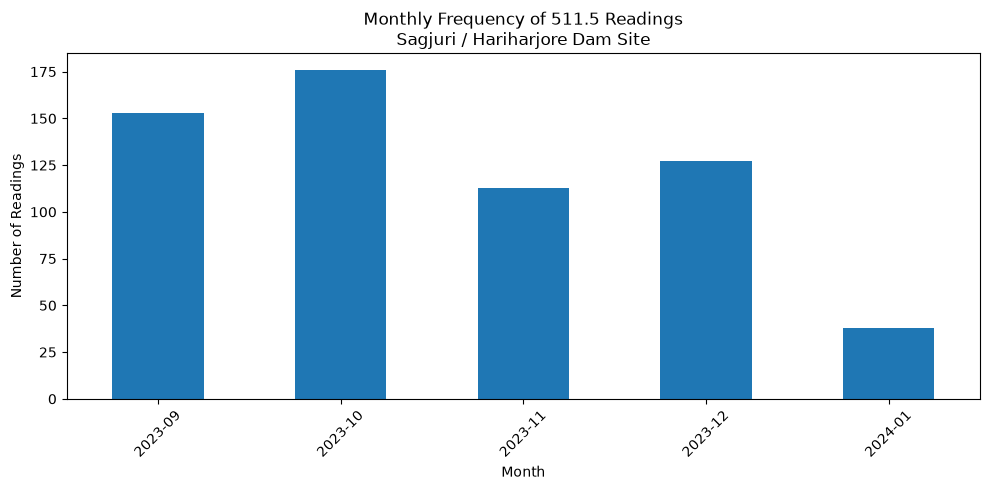

In [40]:
import matplotlib.pyplot as plt

monthly_511.plot(kind="bar", figsize=(10, 5))

plt.title(
    "Monthly Frequency of 511.5 Readings\n"
    "Sagjuri / Hariharjore Dam Site"
)
plt.xlabel("Month")
plt.ylabel("Number of Readings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [41]:
import pandas as pd

rainfall_col = "Telemetry Hourly Rainfall (mm)"

quality_summary = pd.DataFrame({
    "Check": [
        "Total records after exact-duplicate removal",
        "Negative rainfall readings",
        "Readings equal to 511.5",
        "Conflicting station-time groups",
        "Missing values in rainfall column"
    ],
    "Count": [
        len(df_analysis),
        (df_analysis[rainfall_col] < 0).sum(),
        (df_analysis[rainfall_col] == 511.5).sum(),
        len(conflict_summary),
        df_analysis[rainfall_col].isna().sum()
    ]
})

print(quality_summary.to_string(index=False))

                                      Check  Count
Total records after exact-duplicate removal 102492
                 Negative rainfall readings    134
                    Readings equal to 511.5    789
            Conflicting station-time groups    750
          Missing values in rainfall column      0


In [42]:
station_summary = df_analysis.groupby("Station").agg(
    Total_Readings=(rainfall_col, "size"),
    Negative_Readings=(
        rainfall_col, lambda x: (x < 0).sum()
    ),
    Readings_511_5=(
        rainfall_col, lambda x: (x == 511.5).sum()
    ),
    Median_Rainfall=(rainfall_col, "median")
)

station_summary = station_summary.sort_values(
    "Readings_511_5", ascending=False
)

print(station_summary.head(10))

                                Total_Readings  Negative_Readings  \
Station                                                             
Sagjuri / Hariharjore dam site            1990                  0   
Dasarathpur_1                             3189                  1   
Khalikote                                 2108                  1   
Kelo_1                                    1931                  4   
Barunadihi/Dharuadihi                     2118                  2   
Kasipur_1                                 2511                  1   
Maneswar_1                                 926                  0   
Raighar                                   2092                  4   
Koira_1                                   2922                  3   
Kaniha_1                                  2745                  2   

                                Readings_511_5  Median_Rainfall  
Station                                                          
Sagjuri / Hariharjore dam site         

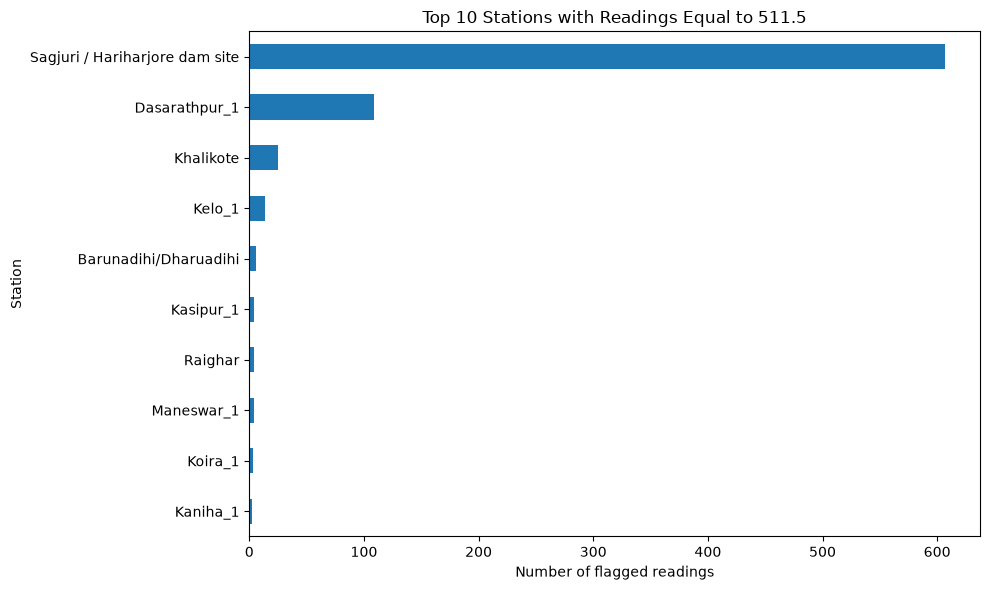

In [43]:
import matplotlib.pyplot as plt

top_stations = station_summary.sort_values(
    "Readings_511_5", ascending=False
).head(10)

top_stations["Readings_511_5"].sort_values().plot(
    kind="barh", figsize=(10, 6)
)

plt.title("Top 10 Stations with Readings Equal to 511.5")
plt.xlabel("Number of flagged readings")
plt.ylabel("Station")
plt.tight_layout()
plt.show()

In [44]:
# Create a separate copy for analysis
df_final = df_analysis.copy()

# Flag negative and unusual readings
df_final["Negative_Flag"] = (
    df_final[rainfall_col] < 0
)

df_final["Value_511_5_Flag"] = (
    df_final[rainfall_col] == 511.5
)

# Add date-related columns
df_final["Year"] = (
    df_final[time_col].dt.year
)

df_final["Month"] = (
    df_final[time_col].dt.month
)

df_final["Month_Name"] = (
    df_final[time_col].dt.month_name()
)

print("Final analysis dataset shape:", df_final.shape)
print("\nFirst 5 rows:")
display(df_final.head())

Final analysis dataset shape: (102492, 25)

First 5 rows:


,SlNo,Station,Agency,State LGD Code,State,District LGD Code,District,Tehsil,Block,Village,...,Local River,Latitude,Longitude,Data Acquisition Time,Telemetry Hourly Rainfall (mm),Year,Month,Negative_Flag,Value_511_5_Flag,Month_Name
0,1,Badanalla_1,Odisha,21,Odisha,370,RAYAGADA,-,-,-,...,-,19.308,83.887,2025-07-05 11:00:00,1.0,2025,7,False,False,July
1,2,Badanalla_1,Odisha,21,Odisha,370,RAYAGADA,-,-,-,...,-,19.308,83.887,2025-07-05 12:00:00,3.0,2025,7,False,False,July
2,3,Badanalla_1,Odisha,21,Odisha,370,RAYAGADA,-,-,-,...,-,19.308,83.887,2025-07-05 23:00:00,2.0,2025,7,False,False,July
3,4,Badanalla_1,Odisha,21,Odisha,370,RAYAGADA,-,-,-,...,-,19.308,83.887,2025-07-06 00:00:00,0.5,2025,7,False,False,July
4,5,Badanalla_1,Odisha,21,Odisha,370,RAYAGADA,-,-,-,...,-,19.308,83.887,2025-07-06 04:00:00,0.5,2025,7,False,False,July


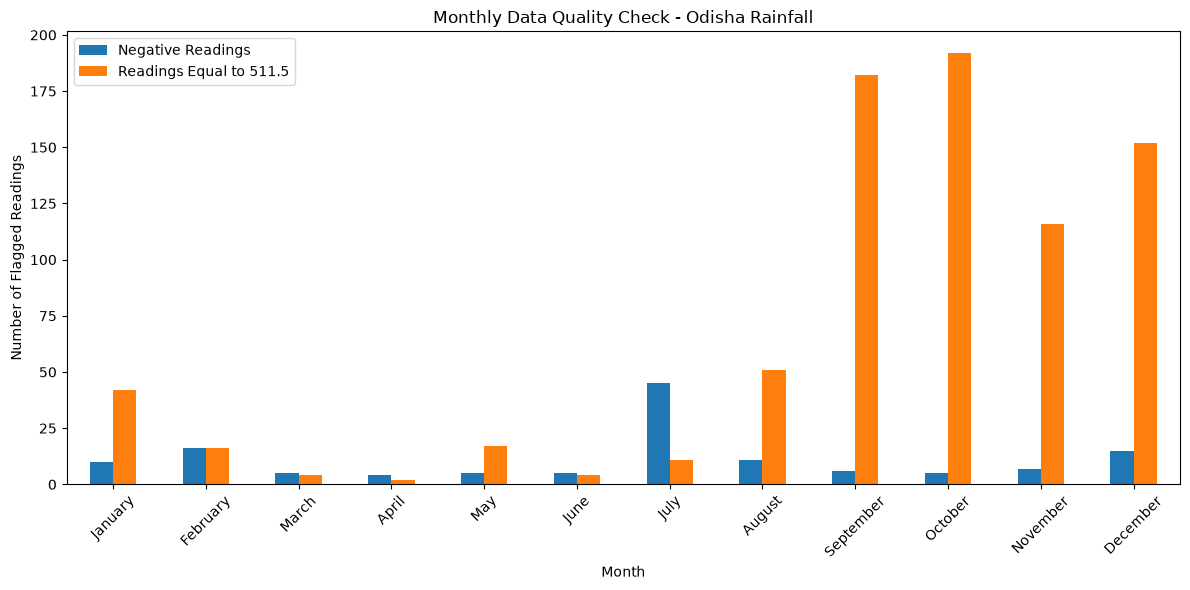

In [45]:
import matplotlib.pyplot as plt

monthly_flags = df_final.groupby("Month_Name").agg(
    Negative_Readings=("Negative_Flag", "sum"),
    Readings_511_5=("Value_511_5_Flag", "sum")
)

month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_flags = monthly_flags.reindex(month_order)

monthly_flags.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Monthly Data Quality Check - Odisha Rainfall")
plt.xlabel("Month")
plt.ylabel("Number of Flagged Readings")
plt.xticks(rotation=45)
plt.legend(["Negative Readings", "Readings Equal to 511.5"])
plt.tight_layout()
plt.show()

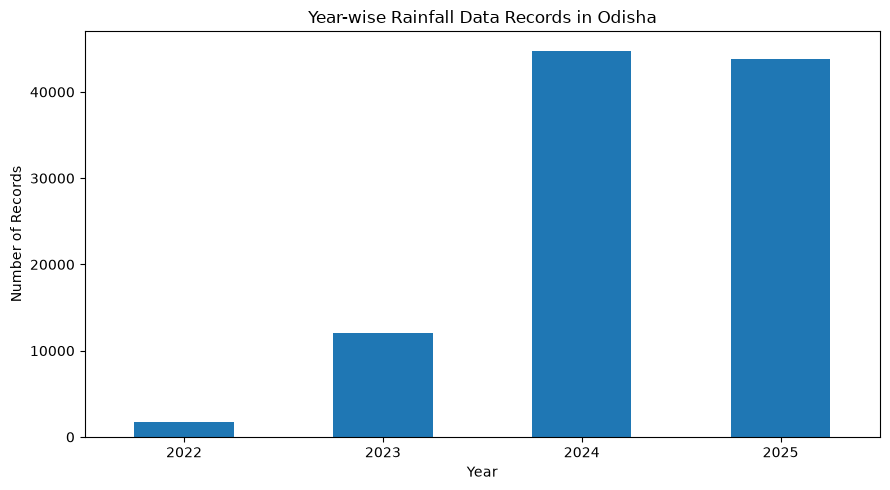

Year
2022     1762
2023    12102
2024    44787
2025    43841
Name: count, dtype: int64


In [46]:
import matplotlib.pyplot as plt

year_counts = df_final["Year"].value_counts().sort_index()

year_counts.plot(kind="bar", figsize=(9, 5))

plt.title("Year-wise Rainfall Data Records in Odisha")
plt.xlabel("Year")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(year_counts)

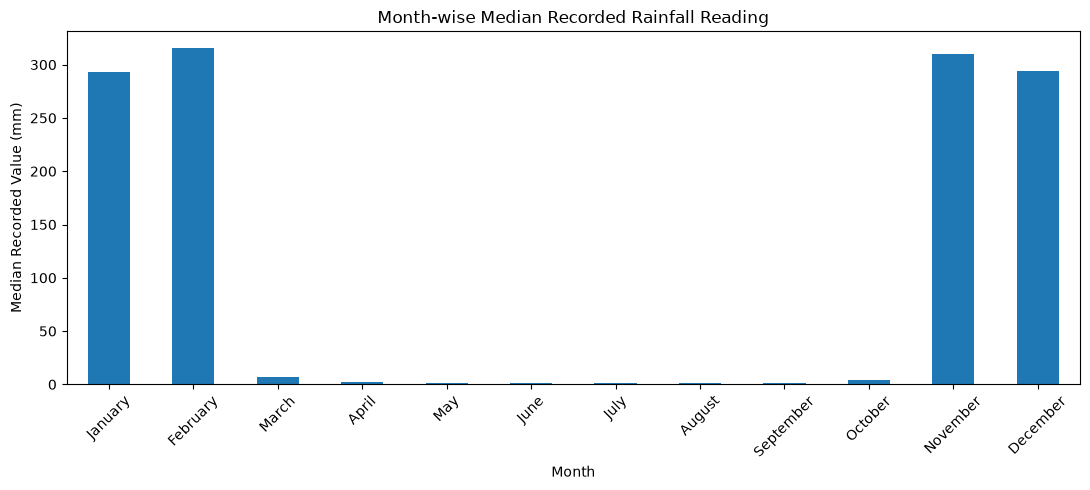

Month_Name
January      293.50
February     315.50
March          6.50
April          2.00
May            1.00
June           1.50
July           1.00
August         1.00
September      1.50
October        4.50
November     309.75
December     294.00
Name: Telemetry Hourly Rainfall (mm), dtype: float64


In [47]:
import matplotlib.pyplot as plt

month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_median = (
    df_final.groupby("Month_Name")[rainfall_col]
    .median()
    .reindex(month_order)
)

monthly_median.plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("Month-wise Median Recorded Rainfall Reading")
plt.xlabel("Month")
plt.ylabel("Median Recorded Value (mm)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(monthly_median)

In [48]:
monthly_year_median = df_final.pivot_table(
    index="Month",
    columns="Year",
    values=rainfall_col,
    aggfunc="median"
)

print(monthly_year_median.round(2))

Year   2022   2023    2024    2025
Month                             
1      35.2    0.5  287.00  295.00
2       NaN    0.5  313.50  316.50
3       NaN    1.0  306.50    6.50
4       NaN    1.0  327.50    1.00
5       NaN    1.0  310.50    0.50
6       1.0    0.5    3.00    1.00
7       1.0    0.5    1.50    1.00
8       1.5    0.5    2.00    1.00
9       1.0    1.5    2.00    1.50
10      1.5    4.5  317.25    1.50
11      2.0    1.0  317.50    1.00
12      0.5  265.0  295.50    0.75


### Year-wise Monthly Median Rainfall Heatmap

This heatmap compares monthly median recorded rainfall values across different years. It helps identify monthly patterns and differences between years. The median is used because it is less affected by extreme values than the mean.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("rainfall_tel_hr_odisha_od_2021_2025.csv")

rainfall_col = "Telemetry Hourly Rainfall (mm)"
time_col = "Data Acquisition Time"

df["Data Acquisition Time"] = pd.to_datetime(
    df["Data Acquisition Time"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

In [6]:
df_analysis = df.drop_duplicates(
    subset=[c for c in df.columns if c != "SlNo"],
    keep="first"
).copy()

df_final = df_analysis.copy()

df_final["Year"] = df_final[time_col].dt.year
df_final["Month"] = df_final[time_col].dt.month
df_final["Hour"] = df_final[time_col].dt.hour

print(df_final.shape)
print(sorted(df_final["Year"].dropna().unique()))

(102492, 23)
[np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]


In [7]:
monthly_year_median = df_final.pivot_table(
    index="Month",
    columns="Year",
    values=rainfall_col,
    aggfunc="median"
).reindex(range(1, 13))

print(monthly_year_median)

Year   2022   2023    2024    2025
Month                             
1      35.2    0.5  287.00  295.00
2       NaN    0.5  313.50  316.50
3       NaN    1.0  306.50    6.50
4       NaN    1.0  327.50    1.00
5       NaN    1.0  310.50    0.50
6       1.0    0.5    3.00    1.00
7       1.0    0.5    1.50    1.00
8       1.5    0.5    2.00    1.00
9       1.0    1.5    2.00    1.50
10      1.5    4.5  317.25    1.50
11      2.0    1.0  317.50    1.00
12      0.5  265.0  295.50    0.75


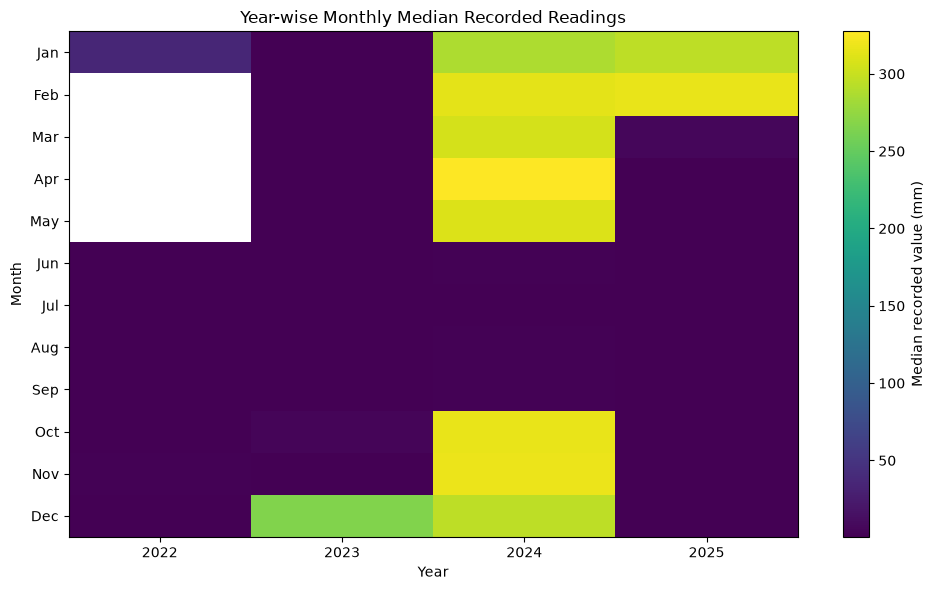

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.imshow(
    monthly_year_median,
    aspect="auto",
    interpolation="nearest"
)

plt.colorbar(label="Median recorded value (mm)")
plt.xticks(
    range(len(monthly_year_median.columns)),
    monthly_year_median.columns
)
plt.yticks(
    range(12),
    [
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
    ]
)

plt.title("Year-wise Monthly Median Recorded Readings")
plt.xlabel("Year")
plt.ylabel("Month")
plt.tight_layout()
plt.show()

### Interpretation of Monthly Median Rainfall Trend

The line graph compares monthly median recorded rainfall values across 2022, 2023, 2024, and 2025. It helps identify monthly variations and differences between years. The median reduces the influence of extreme values compared with the mean, but negative readings and data-quality issues still require attention.

The graph shows recorded data patterns and should not be treated as a confirmed measure of actual rainfall trends without further validation.

In [50]:
year_2024 = df_final[df_final["Year"] == 2024]

check_2024 = year_2024.groupby("Month").agg(
    Total_Records=(rainfall_col, "count"),
    Median_Reading=(rainfall_col, "median"),
    Readings_Above_100=(
        rainfall_col,
        lambda x: (x > 100).sum()
    ),
    Negative_Readings=(
        rainfall_col,
        lambda x: (x < 0).sum()
    )
)

print(check_2024.round(2))

       Total_Records  Median_Reading  Readings_Above_100  Negative_Readings
Month                                                                      
1               1017          287.00                 695                  1
2               1325          313.50                1035                  0
3               1987          306.50                1241                  3
4                996          327.50                 706                  4
5               1961          310.50                1044                  5
6               3011            3.00                 885                  5
7               7741            1.50                1364                 45
8               7018            2.00                1808                 11
9               5565            2.00                1119                  1
10              3436          317.25                2058                  3
11              1541          317.50                1319                  7
12          

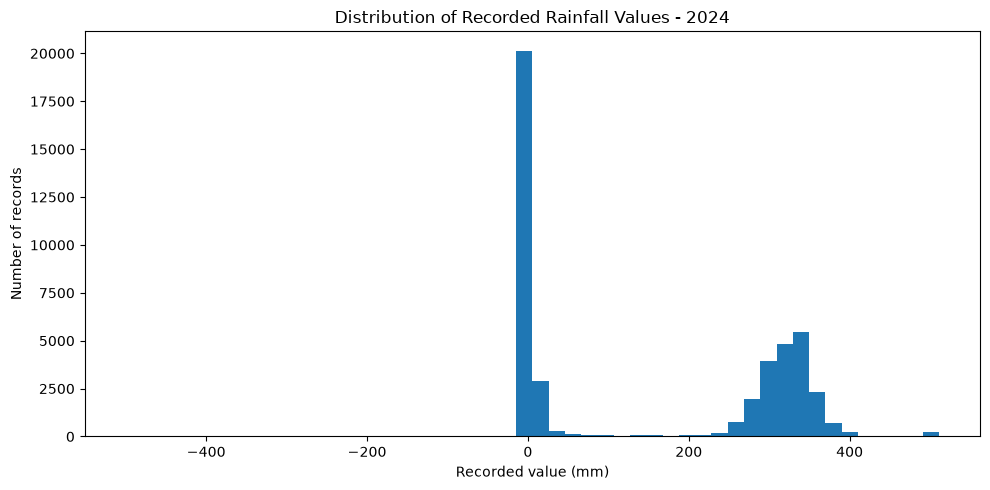

In [51]:
import matplotlib.pyplot as plt

year_2024 = df_final[df_final["Year"] == 2024]

plt.figure(figsize=(10, 5))

plt.hist(
    year_2024[rainfall_col].dropna(),
    bins=50
)

plt.title("Distribution of Recorded Rainfall Values - 2024")
plt.xlabel("Recorded value (mm)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

In [52]:
print(
    year_2024[rainfall_col]
    .describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])
    .round(2)
)

count    44787.00
mean       152.63
std        162.02
min       -500.50
10%          0.50
25%          1.00
50%         13.50
75%        321.50
90%        345.00
max        511.50
Name: Telemetry Hourly Rainfall (mm), dtype: float64


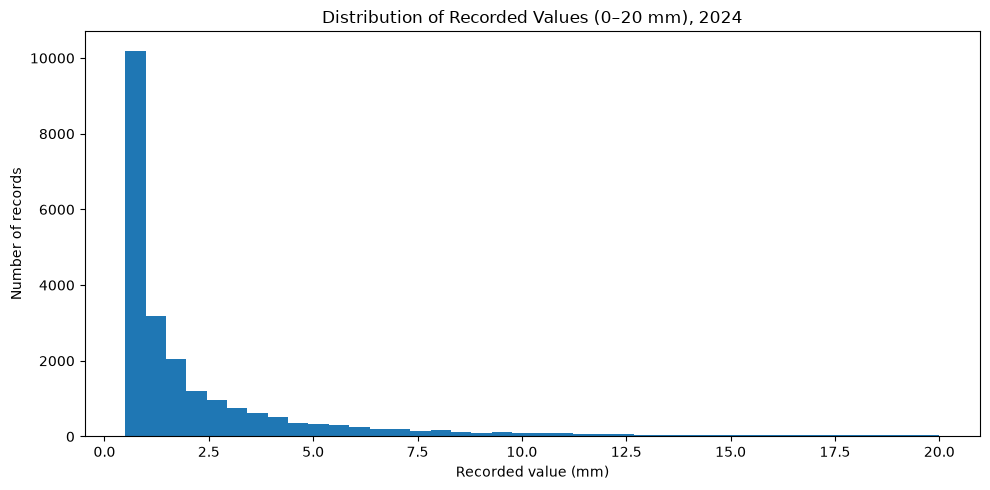

In [53]:
year_2024 = df_final[df_final["Year"] == 2024]

plt.figure(figsize=(10, 5))
plt.hist(
    year_2024.loc[
        (year_2024[rainfall_col] >= 0) &
        (year_2024[rainfall_col] <= 20),
        rainfall_col
    ],
    bins=40
)

plt.title("Distribution of Recorded Values (0–20 mm), 2024")
plt.xlabel("Recorded value (mm)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

### Interpretation of Rainfall Distribution (2024)

This histogram shows the distribution of recorded rainfall values between 0 and 20 mm during 2024. It helps us understand how frequently lower rainfall values were recorded. The analysis excludes negative readings and values above 20 mm for this particular visualization.

In [11]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"

year_2024 = df_final[df_final["Year"] == 2024]

rainfall_2024_low = year_2024.loc[
    (year_2024[rainfall_col] >= 0) &
    (year_2024[rainfall_col] <= 20),
    rainfall_col
]

print("Total records in 2024:", len(year_2024))
print("Records between 0 and 20 mm:", len(rainfall_2024_low))
print("\nStatistical summary:")
print(rainfall_2024_low.describe())

Total records in 2024: 44787
Records between 0 and 20 mm: 22816

Statistical summary:
count    22816.000000
mean         2.289358
std          3.255146
min          0.500000
25%          0.500000
50%          1.000000
75%          2.500000
max         20.000000
Name: Telemetry Hourly Rainfall (mm), dtype: float64


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("rainfall_tel_hr_odisha_od_2021_2025.csv")

rainfall_col = "Telemetry Hourly Rainfall (mm)"
time_col = "Data Acquisition Time"

df[time_col] = pd.to_datetime(
    df[time_col],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

print(df.shape)

(119311, 20)


In [13]:
df_analysis = df.drop_duplicates(
    subset=[c for c in df.columns if c != "SlNo"],
    keep="first"
).copy()

df_final = df_analysis.copy()

df_final["Year"] = df_final[time_col].dt.year
df_final["Month"] = df_final[time_col].dt.month
df_final["Hour"] = df_final[time_col].dt.hour

print(df_final.shape)

(102492, 23)


In [14]:
year_2024 = df_final[df_final["Year"] == 2024]
print("2024 records:", len(year_2024))

2024 records: 44787


In [11]:
print("df available:", "df" in globals())
print("df_analysis available:", "df_analysis" in globals())
print("df_final available:", "df_final" in globals())

df available: True
df_analysis available: False
df_final available: False


In [12]:
df_analysis = df.drop_duplicates(
    subset=[c for c in df.columns if c != "SlNo"],
    keep="first"
).copy()

print("Original dataset:", df.shape)
print("After duplicate removal:", df_analysis.shape)

Original dataset: (119311, 20)
After duplicate removal: (102492, 20)


In [13]:
print(df_analysis["Data Acquisition Time"].dtype)

str


In [14]:
df_analysis["Data Acquisition Time"] = pd.to_datetime(
    df_analysis["Data Acquisition Time"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

In [15]:
df_final = df_analysis.copy()

df_final["Year"] = df_final["Data Acquisition Time"].dt.year
df_final["Month"] = df_final["Data Acquisition Time"].dt.month
df_final["Hour"] = df_final["Data Acquisition Time"].dt.hour

print("df_final shape:", df_final.shape)
print("Available years:", sorted(df_final["Year"].dropna().unique()))

df_final shape: (102492, 23)
Available years: [np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]


In [16]:
year_2024 = df_final[df_final["Year"] == 2024]

### Statistical Summary of Low Rainfall Values (2024)

This analysis summarizes rainfall readings between 0 and 20 mm during 2024. It provides the count, mean, standard deviation, minimum, and quartiles of the selected readings.

In [9]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"

In [10]:
year_2024 = df_final[df_final["Year"] == 2024]

rainfall_2024_low = year_2024.loc[
    (year_2024[rainfall_col] >= 0) &
    (year_2024[rainfall_col] <= 20),
    rainfall_col
]

print("Total records in 2024:", len(year_2024))
print("Records between 0 and 20 mm:", len(rainfall_2024_low))
print("\nStatistical summary:")
print(rainfall_2024_low.describe())

Total records in 2024: 44787
Records between 0 and 20 mm: 22816

Statistical summary:
count    22816.000000
mean         2.289358
std          3.255146
min          0.500000
25%          0.500000
50%          1.000000
75%          2.500000
max         20.000000
Name: Telemetry Hourly Rainfall (mm), dtype: float64


In [18]:
rainfall_col = "Telemetry Hourly Rainfall (mm)"

In [19]:
year_2024 = df_final[df_final["Year"] == 2024]

rainfall_2024_low = year_2024.loc[
    (year_2024[rainfall_col] >= 0) &
    (year_2024[rainfall_col] <= 20),
    rainfall_col
]

print("Total records in 2024:", len(year_2024))
print("Records between 0 and 20 mm:", len(rainfall_2024_low))
print("\nStatistical summary:")
print(rainfall_2024_low.describe())

Total records in 2024: 44787
Records between 0 and 20 mm: 22816

Statistical summary:
count    22816.000000
mean         2.289358
std          3.255146
min          0.500000
25%          0.500000
50%          1.000000
75%          2.500000
max         20.000000
Name: Telemetry Hourly Rainfall (mm), dtype: float64


### Interpretation of Low Rainfall Values in 2024

In 2024, the dataset contains 44,787 records, of which 22,816 recorded rainfall values between 0 and 20 mm. The mean value is approximately 2.29 mm, while the median is 1 mm. This indicates that many readings in this selected range are concentrated at lower values. The maximum value in this group is 20 mm.

**Note:** These results describe only readings between 0 and 20 mm, not all rainfall records in 2024.

In [20]:
print(sorted(df_final["Year"].dropna().unique()))

[np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]


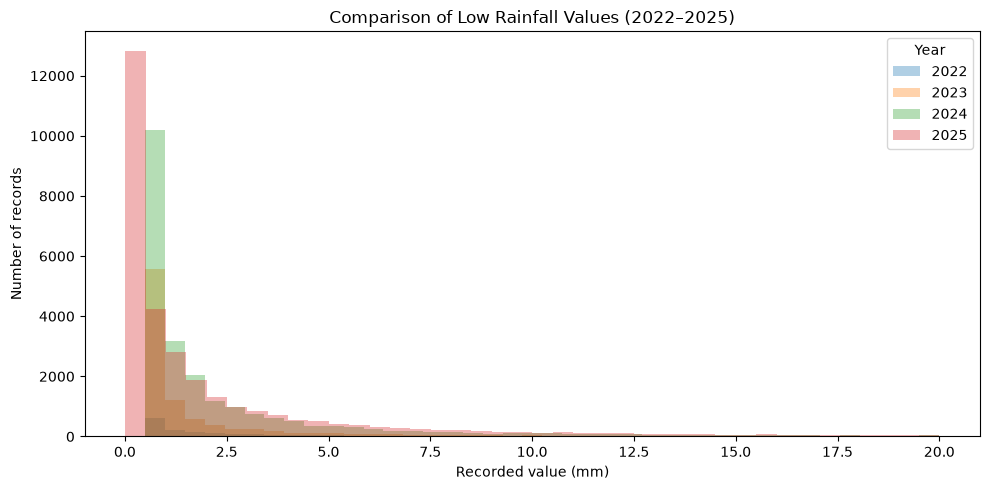

In [21]:
years = [2022, 2023, 2024, 2025]

plt.figure(figsize=(10, 5))

for year in years:
    values = df_final.loc[
        (df_final["Year"] == year) &
        (df_final[rainfall_col] >= 0) &
        (df_final[rainfall_col] <= 20),
        rainfall_col
    ]

    plt.hist(values, bins=40, alpha=0.35, label=str(year))

plt.title("Comparison of Low Rainfall Values (2022–2025)")
plt.xlabel("Recorded value (mm)")
plt.ylabel("Number of records")
plt.legend(title="Year")
plt.tight_layout()
plt.show()

### Year-wise Rainfall Summary (2022–2025)

This analysis compares rainfall records across 2022, 2023, 2024, and 2025. It calculates the number of records, mean, median, minimum, and maximum recorded rainfall for each year to identify differences in the dataset.

In [22]:
yearly_summary = df_final.groupby("Year")[rainfall_col].agg(
    Total_Records="count",
    Mean_Rainfall="mean",
    Median_Rainfall="median",
    Minimum_Rainfall="min",
    Maximum_Rainfall="max"
).round(2)

print(yearly_summary)

      Total_Records  Mean_Rainfall  Median_Rainfall  Minimum_Rainfall  \
Year                                                                    
2022           1762           4.24              1.5               0.5   
2023          12102          72.87              1.0            -479.5   
2024          44787         152.63             13.5            -500.5   
2025          43841          87.25              2.5            -501.0   

      Maximum_Rainfall  
Year                    
2022             409.5  
2023             511.5  
2024             511.5  
2025             511.5  


### Interpretation of Year-wise Rainfall Summary

The dataset contains different numbers of rainfall records across the four years. The highest mean recorded value is observed in 2024 at 152.63 mm, while 2022 has the lowest mean at 4.24 mm. The median is much lower than the mean in 2023, 2024, and 2025, indicating a strongly skewed distribution of recorded values.

Negative readings are present in the dataset and require validation before drawing conclusions about actual rainfall trends. The number of records also varies considerably across years, which limits direct comparisons.

### Year-wise Comparison of Median Rainfall

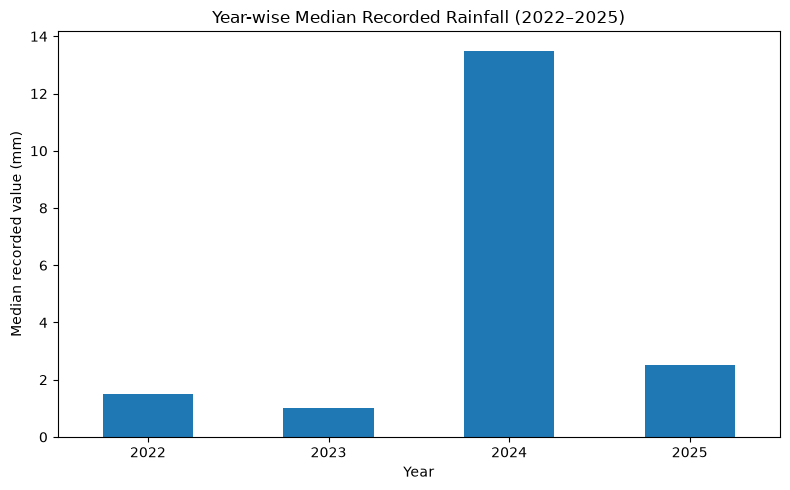

In [24]:
plt.figure(figsize=(8, 5))

yearly_summary["Median_Rainfall"].plot(
    kind="bar",
    rot=0
)

plt.title("Year-wise Median Recorded Rainfall (2022–2025)")
plt.xlabel("Year")
plt.ylabel("Median recorded value (mm)")
plt.tight_layout()
plt.show()

### District-wise Rainfall Analysis

This analysis compares recorded rainfall values across districts of Odisha. It calculates the number of records and average recorded rainfall for each district to identify differences in the available data.

In [25]:
district_summary = df_final.groupby("District")[rainfall_col].agg(
    Total_Records="count",
    Mean_Rainfall="mean",
    Median_Rainfall="median"
).round(2)

district_summary = district_summary.sort_values(
    "Mean_Rainfall",
    ascending=False
)

print(district_summary.head(10))

                Total_Records  Mean_Rainfall  Median_Rainfall
District                                                     
Nabarangapur             2092         274.95           307.50
JAJAPUR                  6776         228.44           305.00
JAGATSINGHAPUR            697         228.43           313.50
SONAPUR                  1990         225.14           277.25
ANUGUL                   3432         206.51           294.00
BALANGIR                 2803         185.77           285.00
RAYAGADA                 7798         181.91           274.00
CUTTACK                  4755         157.53            19.00
KENDUJHAR                7733         154.71            18.00
Baleshwar                5307         143.45            11.00


### Visualization of District-wise Recorded Rainfall

This horizontal bar chart compares the mean recorded rainfall values for the ten districts ranked highest by mean. The results should be interpreted cautiously because unusual or negative readings and unequal record counts may affect the ranking.

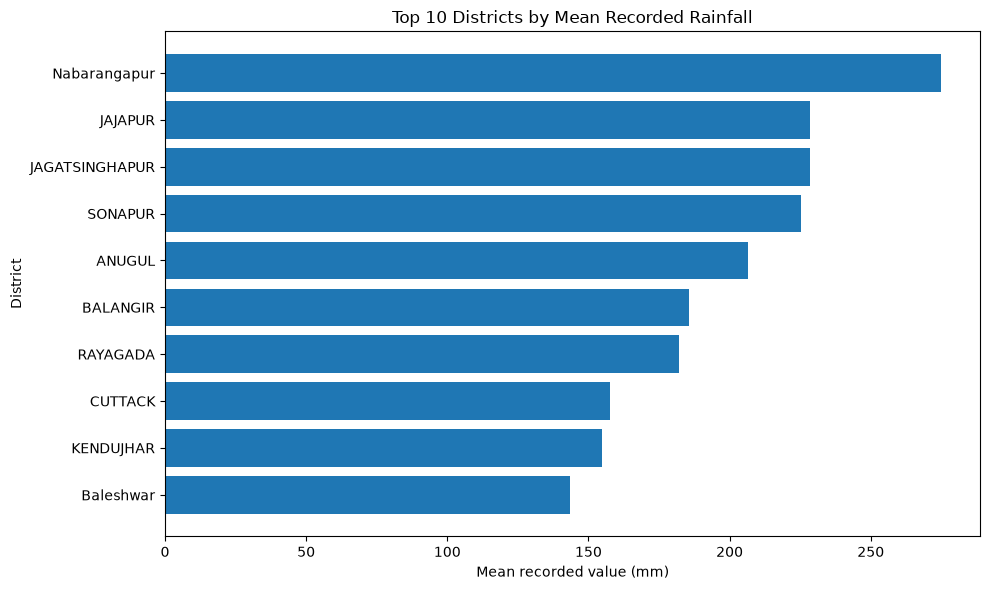

In [26]:
top_districts = district_summary.head(10).sort_values(
    "Mean_Rainfall",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_districts.index.astype(str),
    top_districts["Mean_Rainfall"]
)

plt.title("Top 10 Districts by Mean Recorded Rainfall")
plt.xlabel("Mean recorded value (mm)")
plt.ylabel("District")
plt.tight_layout()
plt.show()

In [15]:
print("Rainfall distribution summary:")
print(df_final[rainfall_col].describe())

print("\nSkewness:")
print(df_final[rainfall_col].skew())

Rainfall distribution summary:
count    102492.000000
mean        112.698081
std         153.715382
min        -501.000000
25%           0.500000
50%           3.000000
75%         298.000000
max         511.500000
Name: Telemetry Hourly Rainfall (mm), dtype: float64

Skewness:
0.723648621522325


### Rainfall Distribution Analysis

The rainfall data contains 102,492 records. The mean recorded value is 112.70 mm, while the median is only 3.00 mm. This large difference suggests that the distribution is influenced by high recorded values.

The minimum value is -501.0 mm, which is physically unusual for rainfall and requires data-quality verification. The maximum value is 511.5 mm, which should also be checked against the source documentation.

The skewness is 0.72, indicating a positively skewed distribution. However, unusual or repeated values may affect these statistics.

In [16]:
print("Zero rainfall records:",
      (df_final[rainfall_col] == 0).sum())

print("Negative rainfall records:",
      (df_final[rainfall_col] < 0).sum())

print("Positive rainfall records:",
      (df_final[rainfall_col] > 0).sum())

print("Records above 100 mm:",
      (df_final[rainfall_col] > 100).sum())

Zero rainfall records: 0
Negative rainfall records: 134
Positive rainfall records: 102358
Records above 100 mm: 35583


### Analysis of Rainfall Value Categories

- The dataset contains 102,492 rainfall records.
- There are 134 negative readings, which require data-quality verification.
- No records have an exact value of 0 mm.
- A total of 102,358 records have positive values.
- 35,583 records have values above 100 mm, so these readings should be examined carefully.

These results describe the recorded values in the dataset. Negative readings and unusually high values should be verified before drawing conclusions about actual rainfall patterns.

In [17]:
yearly_summary = df_final.groupby("Year")[rainfall_col].agg(
    Total_Records="count",
    Mean_Rainfall="mean",
    Median_Rainfall="median"
).round(2)

print(yearly_summary)

      Total_Records  Mean_Rainfall  Median_Rainfall
Year                                               
2022           1762           4.24              1.5
2023          12102          72.87              1.0
2024          44787         152.63             13.5
2025          43841          87.25              2.5


### Bivariate Analysis: Year-wise Rainfall Comparison

- 2022 has 1,762 records, with a mean of 4.24 mm and median of 1.5 mm.
- 2023 has 12,102 records, with a mean of 72.87 mm and median of 1.0 mm.
- 2024 has the highest number of records (44,787) and the highest mean (152.63 mm).
- 2025 has 43,841 records, with a mean of 87.25 mm and median of 2.5 mm.
- The mean is much higher than the median in 2023, 2024, and 2025, suggesting that high recorded values influence the average.

The number of records differs considerably across years. Therefore, these results alone cannot establish that actual rainfall increased or decreased over time.

In [18]:
correlation_data = df_final[
    [rainfall_col, "Year", "Month", "Hour"]
].corr(numeric_only=True)

print(correlation_data.round(2))

                                Telemetry Hourly Rainfall (mm)  Year  Month  \
Telemetry Hourly Rainfall (mm)                            1.00 -0.02  -0.13   
Year                                                     -0.02  1.00  -0.37   
Month                                                    -0.13 -0.37   1.00   
Hour                                                     -0.02 -0.03   0.00   

                                Hour  
Telemetry Hourly Rainfall (mm) -0.02  
Year                           -0.03  
Month                           0.00  
Hour                            1.00  


### Correlation Analysis

Correlation measures the strength and direction of a linear relationship between two variables. Values closer to +1 indicate a positive relationship, values closer to -1 indicate a negative relationship, and values near 0 indicate a weak linear relationship.

Key observations:

- Rainfall and Year have a correlation of -0.02, indicating almost no linear relationship.
- Rainfall and Month have a correlation of -0.13, indicating a weak negative linear relationship.
- Rainfall and Hour have a correlation of -0.02, indicating almost no linear relationship.
- Year and Month have a correlation of -0.37. This may reflect differences in the months represented across years in the dataset.

These correlations do not establish causation. The results should be interpreted cautiously because the dataset contains unusual rainfall readings and unequal numbers of records across years.

In [19]:
monthly_year_median = df_final.pivot_table(
    index="Month",
    columns="Year",
    values=rainfall_col,
    aggfunc="median"
).reindex(range(1, 13))

print(monthly_year_median.round(2))

Year   2022   2023    2024    2025
Month                             
1      35.2    0.5  287.00  295.00
2       NaN    0.5  313.50  316.50
3       NaN    1.0  306.50    6.50
4       NaN    1.0  327.50    1.00
5       NaN    1.0  310.50    0.50
6       1.0    0.5    3.00    1.00
7       1.0    0.5    1.50    1.00
8       1.5    0.5    2.00    1.00
9       1.0    1.5    2.00    1.50
10      1.5    4.5  317.25    1.50
11      2.0    1.0  317.50    1.00
12      0.5  265.0  295.50    0.75


### Multivariate Analysis: Monthly and Year-wise Comparison

- The monthly median recorded values vary considerably across years.
- In 2022, the available January median is 35.2 mm, while several later months have much lower medians.
- In 2023, December has a high median of 265.0 mm compared with most other months.
- In 2024, several months have unusually high median values above 287 mm, while June to September have much lower values.
- In 2025, January and February have high median values, whereas March to December mostly have low values.
- Missing values for some months indicate that no usable records were available for those month-year combinations.

These unusual differences require further validation against the original data source before interpreting them as actual rainfall patterns.

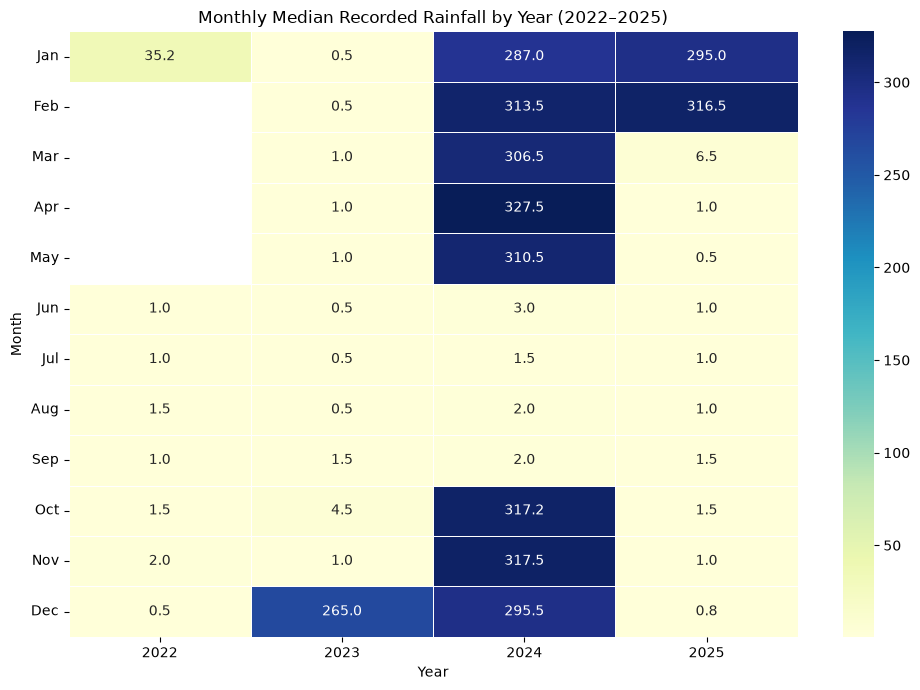

In [20]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    monthly_year_median,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Monthly Median Recorded Rainfall by Year (2022–2025)")
plt.xlabel("Year")
plt.ylabel("Month")
plt.yticks(
    ticks=[i + 0.5 for i in range(12)],
    labels=["Jan", "Feb", "Mar", "Apr", "May", "Jun",
            "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    rotation=0
)
plt.tight_layout()
plt.show()

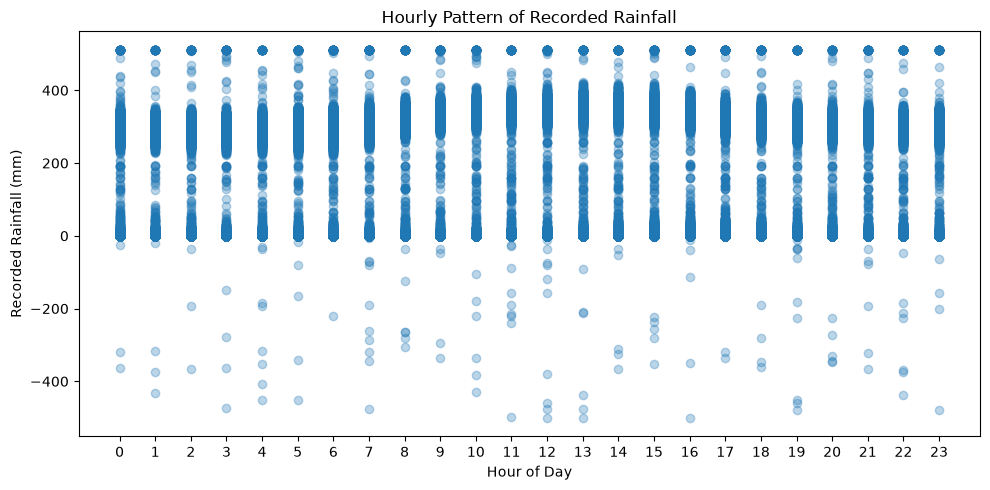

In [21]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df_final["Hour"],
    df_final[rainfall_col],
    alpha=0.3
)

plt.title("Hourly Pattern of Recorded Rainfall")
plt.xlabel("Hour of Day")
plt.ylabel("Recorded Rainfall (mm)")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

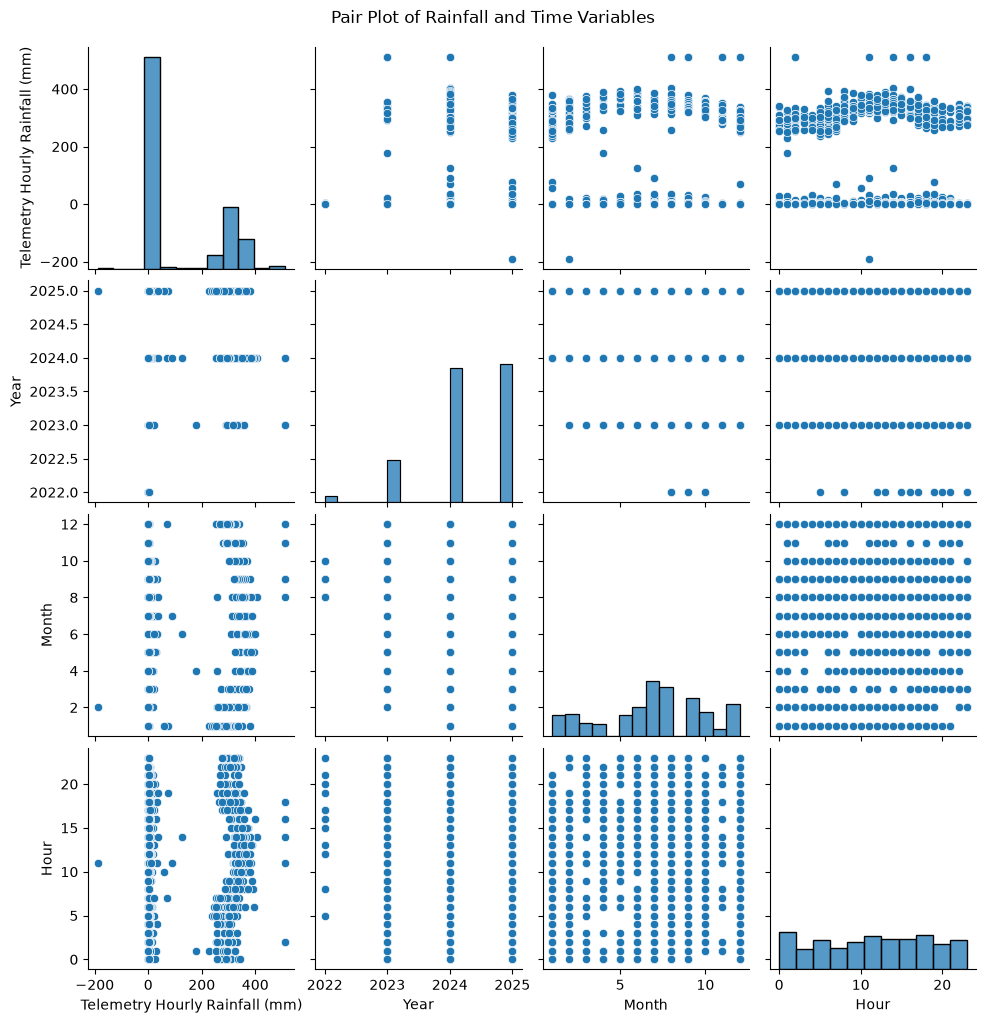

In [22]:
pair_data = df_final[
    [rainfall_col, "Year", "Month", "Hour"]
].dropna()

sns.pairplot(
    pair_data.sample(
        n=min(1000, len(pair_data)),
        random_state=42
    ),
    diag_kind="hist"
)

plt.suptitle(
    "Pair Plot of Rainfall and Time Variables",
    y=1.02
)
plt.show()

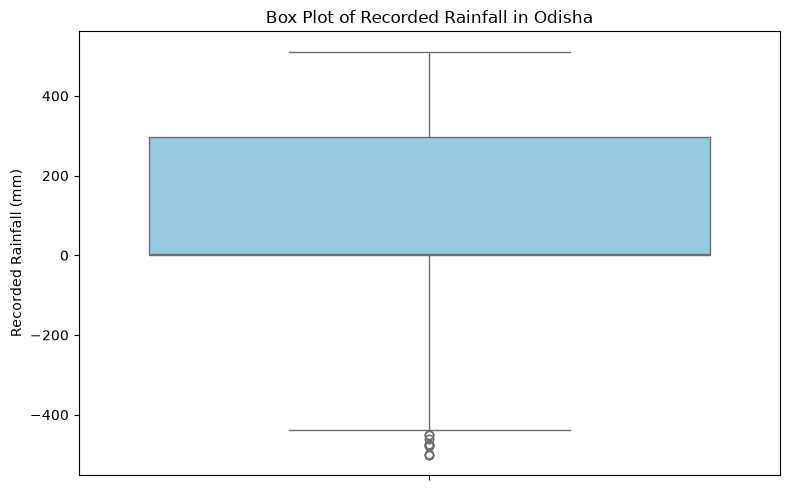

In [23]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    y=df_final[rainfall_col],
    color="skyblue"
)

plt.title("Box Plot of Recorded Rainfall in Odisha")
plt.ylabel("Recorded Rainfall (mm)")
plt.tight_layout()
plt.show()

# Section 5: AI Tool Integration

## 5.1 AI Tool Used

ChatGPT was used as an AI assistance tool to help interpret statistical results, explain correlation values, and improve the clarity of the project's findings.

## 5.2 Prompt Given to the AI Tool

"Analyze the following rainfall dataset summary: 102,492 records, mean recorded value of 112.70 mm, median of 3.00 mm, minimum of -501 mm, maximum of 511.5 mm, and skewness of 0.72. Explain the distribution, identify possible data-quality concerns, and suggest appropriate conclusions without assuming that unusual values are valid rainfall measurements."

## 5.3 AI-Generated Response

The dataset has a mean recorded value substantially higher than its median, suggesting that high values influence the average. The positive skewness indicates some asymmetry in the distribution. Negative rainfall readings are physically unusual and should be investigated. Repeated high values may also require validation. The findings should be treated as patterns in recorded data until the data quality is confirmed.

## 5.4 Evaluation of AI Response

The AI response is consistent with the descriptive statistics and helps explain why the mean and median differ. It correctly identifies negative readings and repeated high values as potential data-quality concerns. However, the response cannot confirm whether these values are errors without checking the original source documentation.

Therefore, AI was used as a supporting tool, while the numerical results were obtained from Python and the dataset.

## Key Findings

1. The dataset contains hourly telemetry rainfall records for Odisha from 2022 to 2025.
2. The number of available records varies considerably across years, with 2024 and 2025 containing substantially more records than 2022.
3. In 2024, 22,816 records fall within the selected range of 0–20 mm.
4. The mean recorded rainfall value in 2024 is higher than in the other years included in the analysis.
5. Negative rainfall values and repeated station-time records were identified during data quality checks.
6. The recorded value of 511.5 mm appears in multiple years and should be validated against the source documentation before being interpreted as actual rainfall.

These findings describe the available dataset. Differences in record counts and potentially invalid readings should be considered before drawing conclusions about rainfall patterns across Odisha.

## Conclusion

This project analyzed hourly telemetry rainfall data for Odisha using Python, Pandas, Matplotlib, and Seaborn. The analysis included data inspection, quality checks, rainfall distribution, and year-wise and district-wise comparisons.

The project demonstrates how data analysis can help identify patterns and data quality issues in rainfall records. However, negative readings, unusual values, and differences in yearly record counts limit direct comparisons. Further validation of the source data is necessary before drawing conclusions about actual rainfall trends.

In [28]:
print("Original dataset:", df.shape)
print("Analysis dataset:", df_analysis.shape)
print("Final dataset:", df_final.shape)

print("\nMissing timestamps:", df_final["Data Acquisition Time"].isna().sum())
print("Missing rainfall values:", df_final[rainfall_col].isna().sum())
print("Available years:", sorted(df_final["Year"].dropna().unique()))

Original dataset: (119311, 20)
Analysis dataset: (102492, 20)
Final dataset: (102492, 23)

Missing timestamps: 0
Missing rainfall values: 0
Available years: [np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]
